In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [2]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
print(len(words))
print(words[:4])

32033
['emma', 'olivia', 'ava', 'isabella']


In [3]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(stoi)
print(vocab_size)
print(stoi)
print(itos)

27
{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [4]:
# shuffle up the words
import random
random.seed(42)
random.shuffle(words)

In [5]:
block_size = 8
def build_dataset(words):
    X, Y = [], []
    for word in words:
        context = [0]*block_size
        for ch in word + '.':
            X.append(context)
            Y.append(stoi[ch])
            context = context[1:] + [stoi[ch]]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X,Y

n1 = int(len(words)*0.8)
n2 = int(len(words)*0.9)
Xtr, Ytr = build_dataset(words[:n1])
XVal, YVal = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])
print(Xtr[:4])

torch.Size([182625, 8]) torch.Size([182625])
torch.Size([22655, 8]) torch.Size([22655])
torch.Size([22866, 8]) torch.Size([22866])
tensor([[ 0,  0,  0,  0,  0,  0,  0,  0],
        [ 0,  0,  0,  0,  0,  0,  0, 25],
        [ 0,  0,  0,  0,  0,  0, 25, 21],
        [ 0,  0,  0,  0,  0, 25, 21,  8]])


In [6]:
for x, y, in zip(Xtr[:20], Ytr[:20]):
    print(f"{''.join([itos[ix.item()] for ix in x])} ---> {itos[y.item()]}")

........ ---> y
.......y ---> u
......yu ---> h
.....yuh ---> e
....yuhe ---> n
...yuhen ---> g
..yuheng ---> .
........ ---> d
.......d ---> i
......di ---> o
.....dio ---> n
....dion ---> d
...diond ---> r
..diondr ---> e
.diondre ---> .
........ ---> x
.......x ---> a
......xa ---> v
.....xav ---> i
....xavi ---> e


In [7]:
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):
        self.weights = torch.randn([fan_in, fan_out])/fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias is True else None

    def __call__(self, x):
        self.out = x @ self.weights
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        self.parameters = [self.weights] + ([] if self.bias is None else [self.bias])
        return self.parameters


class BatchNorm1D:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True

        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

        self.running_mean = torch.zeros([1, dim])
        self.running_var = torch.ones([1, dim])

    def __call__(self, x):

        if x.ndim == 2:
            dim = 0
        elif x.ndim == 3:
            dim = (0,1)
        
        if self.training:
            xmean = x.mean(dim, keepdim=True)
            xvar = x.var(dim, keepdim=True)
        else:
            xmean = self.running_mean
            xvar = self.running_var

        xhat = (x - xmean)/torch.sqrt(xvar + self.eps)
        self.out = self.gamma*xhat + self.beta

        if self.training:
            with torch.no_grad():
                self.running_mean = (1-self.momentum)*self.running_mean + self.momentum*xmean
                self.running_var = (1-self.momentum)*self.running_var + self.momentum*xvar
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]


class Tanh:

    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

class Embedding:

    def __init__(self, num_dimensions, num_embeddings):
        self.weights = torch.randn([num_dimensions, num_embeddings])

    def __call__(self, IX):
        self.out = self.weights[IX]
        return self.out

    def parameters(self):
        return [self.weights]

class FlattenConsecutive:

    def __init__(self, n):
        self.n = n

    def __call__(self, x):
        A,B,C = x.shape
        x = x.view(A, B//self.n, C*self.n)
        if x.shape[1] == 1:
            x = x.squeeze(1)
        self.out = x
        return self.out

    def parameters(self):
        return []


class Sequential:

    def __init__(self, layers):
        self.layers = layers
    
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [8]:
torch.manual_seed(42)

In [9]:
n_embd = 10
n_hidden = 68

batch_size = 32

model = Sequential([
    Embedding(vocab_size, n_embd),
    FlattenConsecutive(2), Linear(n_embd*2, n_hidden, bias=False), BatchNorm1D(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden*2, n_hidden, bias=False), BatchNorm1D(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden*2, n_hidden, bias=False), BatchNorm1D(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size)
])

with torch.no_grad():
    model.layers[-1].weights *= 0.1

parameters = model.parameters()
for p in parameters:
    p.requires_grad = True

print(sum(p.nelement() for p in parameters))

22397


In [10]:
max_steps = 200000
lossi = []
ud = []

for i in range(max_steps):
    #mini batch
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, Yb = Xtr[ix], Ytr[ix]

    #forward pass
    logits = model(Xb)
    loss = F.cross_entropy(logits, Yb)
    
    #backward pass
    for layer in model.layers:
        layer.out.retain_grad()
    for p in parameters:
        p.grad = None

    loss.backward()

    #gradient updates
    lr = 0.1 if i<150000 else 0.01
    for p in parameters:
        p.data += -lr*p.grad

    #telemetry
    if i%10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item(): .4f}')
    
    lossi.append(loss.log10().item())
    with torch.no_grad():
        ud.append([((lr*p.grad).std()/p.data.std()).log10().item() for p in parameters])

      0/ 200000:  3.3142
  10000/ 200000:  2.2096
  20000/ 200000:  2.1495
  30000/ 200000:  2.1232
  40000/ 200000:  1.9629
  50000/ 200000:  2.4183
  60000/ 200000:  1.9633
  70000/ 200000:  1.8960
  80000/ 200000:  2.1884
  90000/ 200000:  1.8161
 100000/ 200000:  1.5931
 110000/ 200000:  2.3607
 120000/ 200000:  2.3670
 130000/ 200000:  1.9098
 140000/ 200000:  2.2285
 150000/ 200000:  1.7118
 160000/ 200000:  1.8517
 170000/ 200000:  1.9997
 180000/ 200000:  2.1043
 190000/ 200000:  1.6969


In [66]:
for layer in model.layers:
    print(f"{layer.__class__.__name__}: {layer.out.shape}")

Embedding: torch.Size([32, 8, 10])
FlattenConsecutive: torch.Size([32, 4, 20])
Linear: torch.Size([32, 4, 68])
BatchNorm1D: torch.Size([32, 4, 68])
Tanh: torch.Size([32, 4, 68])
FlattenConsecutive: torch.Size([32, 2, 136])
Linear: torch.Size([32, 2, 68])
BatchNorm1D: torch.Size([32, 2, 68])
Tanh: torch.Size([32, 2, 68])
FlattenConsecutive: torch.Size([32, 136])
Linear: torch.Size([32, 68])
BatchNorm1D: torch.Size([32, 68])
Tanh: torch.Size([32, 68])
Linear: torch.Size([32, 27])


Embedding: torch.Size([32, 8, 10])
FlattenConsecutive: torch.Size([32, 4, 20])
Linear: torch.Size([32, 4, 68])
BatchNorm1D: torch.Size([32, 4, 68])
Tanh: torch.Size([32, 4, 68])
FlattenConsecutive: torch.Size([32, 2, 136])
Linear: torch.Size([32, 2, 68])
BatchNorm1D: torch.Size([32, 2, 68])
Tanh: torch.Size([32, 2, 68])
FlattenConsecutive: torch.Size([32, 136])
Linear: torch.Size([32, 68])
BatchNorm1D: torch.Size([32, 68])
Tanh: torch.Size([32, 68])
Linear: torch.Size([32, 27])


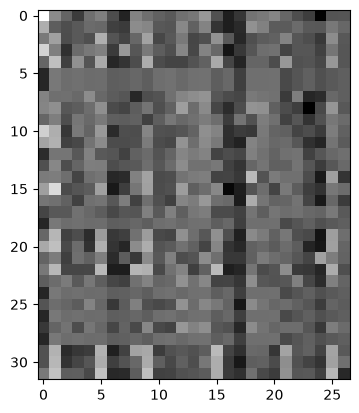

In [69]:
# for layer in model.layers:
#     print(f"{layer.__class__.__name__}: {layer.out.shape}")
#     plt.imshow(layer.out.detach().view(layer.out.shape[0], -1), cmap='gray')

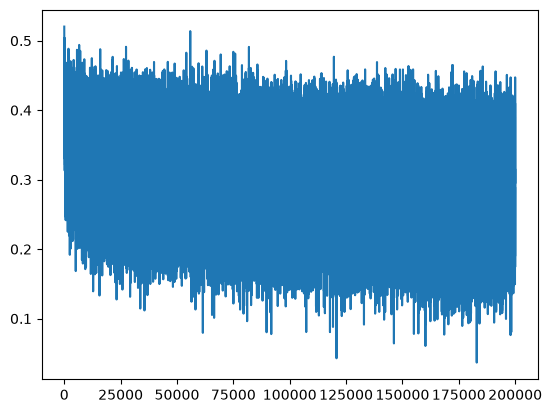

In [70]:
plt.plot(lossi)

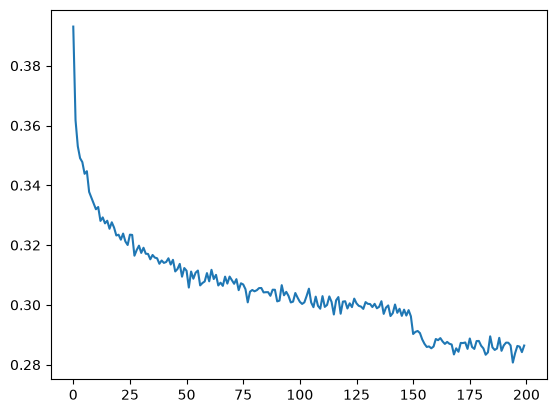

In [71]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(dim=1))

In [72]:
# put layers into eval mode
for layer in model.layers:
  layer.training = False

In [73]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (XVal, YVal),
    'test': (Xte, Yte),
  }[split]
  logits = model(x)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 1.9110119342803955
val 2.0201919078826904


In [74]:
for _ in range(20):
    context = [0]*block_size
    word = []
    while(len(word)==0 or word[-1] != '.'):
        logits = model(torch.tensor([context]))
        probs = F.softmax(logits, dim=1)
        
        ix = torch.multinomial(probs, num_samples=1).item()
        word += [itos[ix]]
        context = context[1:] + [ix]
    print(''.join(word))

kamorah.
khani.
stentar.
jaslaun.
hemir.
fynner.
matharynni.
blaylak.
hason.
celvina.
raleah.
terma.
jaylan.
chantley.
coujahnim.
annalyze.
gwindro.
pennessa.
arhen.
tokore.


In [ ]:
# on block_size = 3, [embd(27*10), linear(200), batchnorm, tanh, linear(27), cross_entropy], batch_size = 32
train 2.0583250522613525
val 2.1065292358398438

# on block_size = 8, [embd(27*10), linear(200), batchnorm, tanh, linear(27), cross_entropy], batch_size = 32
train 1.9163438081741333
val 2.034247636795044

# on block_size = 8, 
# n_embd = 10
# n_hidden = 68

# batch_size = 32

# model = Sequential(layers = [
#     Embedding(vocab_size, n_embd),
#     FlattenConsecutive(2), Linear(n_embd*2, n_hidden, bias=False), BatchNorm1D(n_hidden), Tanh(),
#     FlattenConsecutive(2), Linear(n_hidden*2, n_hidden, bias=False), BatchNorm1D(n_hidden), Tanh(),
#     FlattenConsecutive(2), Linear(n_hidden*2, n_hidden, bias=False), BatchNorm1D(n_hidden), Tanh(),
#     Linear(n_hidden, vocab_size)
# ])

train 1.9110119342803955
val 2.0201919078826904

In [87]:
vowels = [stoi[x] for x in list("aeiou")]
x = torch.stack(list(filter(lambda x: x[-1].item() in vowels, Xtr[:20])))
x.shape

torch.Size([7, 8])

In [83]:
logits = model(x)

AttributeError: AxesImage.set() got an unexpected keyword argument 'figsize'

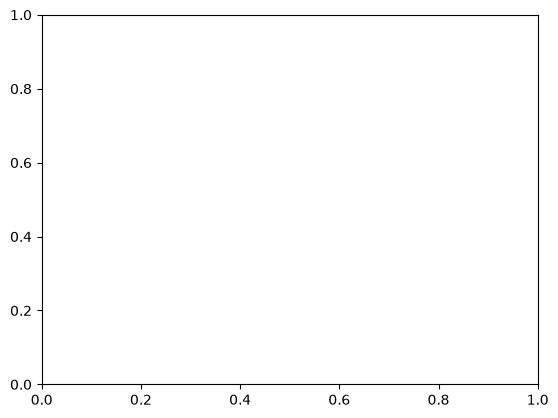

In [99]:
tanh_layers = list(filter(lambda layer: layer.__class__.__name__ == 'Tanh', model.layers))
tanh_layer = tanh_layers[0]
plt.imshow(tanh_layer.out.detach().view(tanh_layer.out.shape[0], -1).numpy(), cmap='gray', figsize=(10, 6))

torch.Size([7, 4, 68])
torch.Size([7, 2, 68])
torch.Size([7, 68])


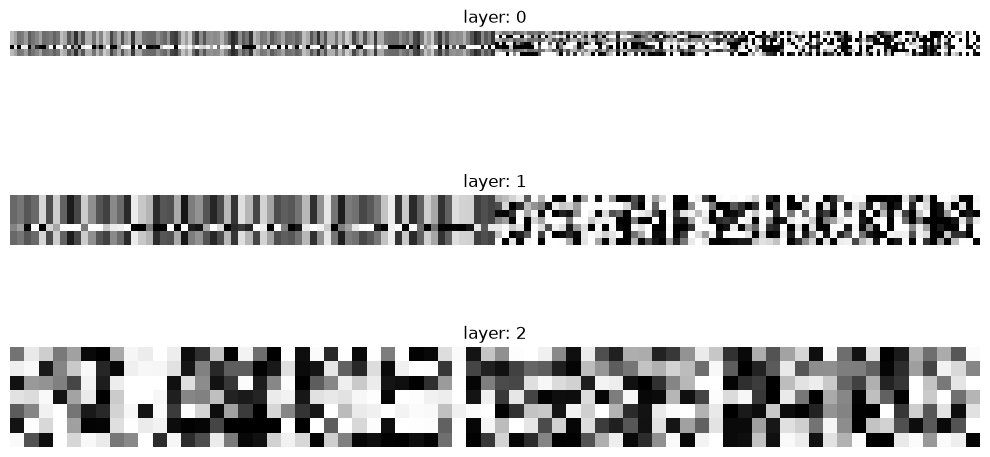

In [94]:
# fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(10, 6))
# ix = 0
# for layer in model.layers:
#     if layer.__class__.__name__ == 'Tanh':
#         print(layer.out.shape)
#         ax[ix].imshow(layer.out.detach().view(layer.out.shape[0], -1).numpy(), cmap='gray')
#         ax[ix].set_title(f"layer: {ix}")
#         ax[ix].axis('off')
#         ix += 1

# plt.tight_layout()
# plt.show()